# GAN Lab: Synthetic Image Generation with MNIST
Runtime: Colab, then Runtime > Change runtime type > GPU (T4). Run the cells in order.

## PART A: Dataset Preparation and Image Preprocessing

I0000 00:00:1791208264.816151   25288 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791208264.816751   25288 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791208264.848699   25288 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791208265.884777   25288 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Submitted by: 24BAD405
TensorFlow: 2.22.0-rc0
Training images : (60000, 28, 28)
Test images     : (10000, 28, 28)
Image size      : (28, 28) | dtype: uint8
Pixel range     : 0 to 255

Images per digit class:
          0     1     2     3     4     5     6     7     8     9
count  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949


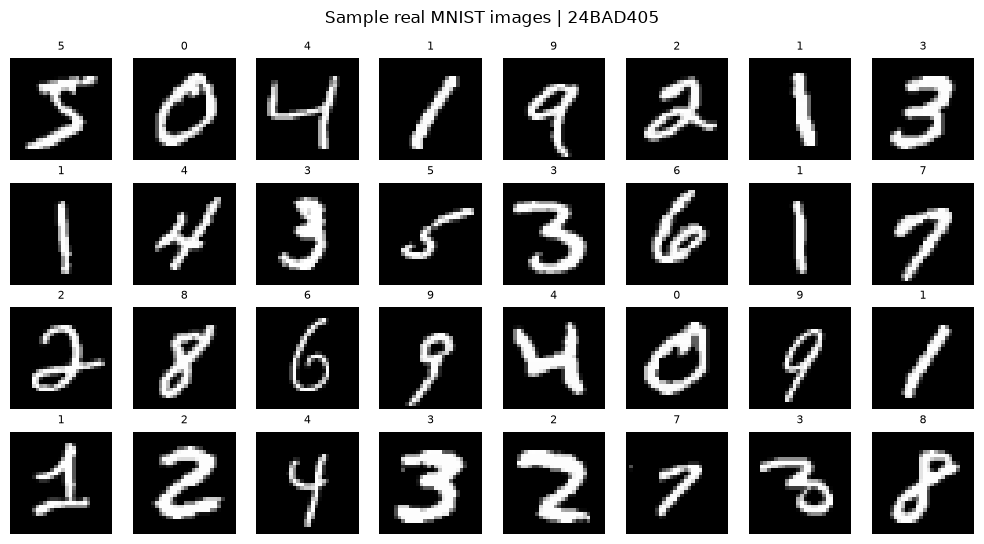


After preprocessing: (60000, 28, 28, 1) | min: -1.0 | max: 1.0
Batches per epoch: 234 | batch shape: (256, 28, 28, 1)


E0000 00:00:1791208268.211066   25288 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1791208268.211636   25337 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1791208268.227820   25288 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory
W0000 00:00:1791208268.227857   2528

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ====== EDIT THIS: student roll numbers ======
ROLL_NOS = ["24BAD405"]
print("Submitted by:", ", ".join(ROLL_NOS))
print("TensorFlow:", tf.__version__)

tf.random.set_seed(42); np.random.seed(42)

# 1. Load MNIST (labels are not needed for GAN training, only for exploration)
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()

# 2-3. Explore: count and dimensions
print("Training images :", train_images.shape)
print("Test images     :", test_images.shape)
print("Image size      :", train_images.shape[1:], "| dtype:", train_images.dtype)
print("Pixel range     :", train_images.min(), "to", train_images.max())
print("\nImages per digit class:")
print(pd.Series(train_labels).value_counts().sort_index().to_frame("count").T)

# 4. Display sample images
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images[i], cmap="gray"); ax.set_title(int(train_labels[i]), fontsize=8); ax.axis("off")
plt.suptitle(f"Sample real MNIST images | {', '.join(ROLL_NOS)}")
plt.tight_layout(); plt.show()

# 5-6. Reshape to (N, 28, 28, 1) and normalize to [-1, 1] (matches tanh output of the Generator)
train_images = train_images.reshape(-1, 28, 28, 1).astype("float32")
train_images = (train_images - 127.5) / 127.5
print("\nAfter preprocessing:", train_images.shape, "| min:", train_images.min(), "| max:", train_images.max())

# 7-8. Batch-wise data pipeline with tf.data
BUFFER_SIZE = train_images.shape[0]
BATCH_SIZE = 256
train_dataset = (tf.data.Dataset.from_tensor_slices(train_images)
                 .shuffle(BUFFER_SIZE)
                 .batch(BATCH_SIZE, drop_remainder=True)
                 .prefetch(tf.data.AUTOTUNE))
print("Batches per epoch:", len(train_dataset), "| batch shape:", next(iter(train_dataset)).shape)

## PART B: Implementing the Generator

Submitted by: 24BAD405


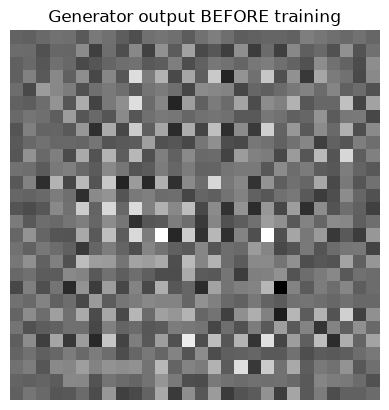

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [2]:
print("Submitted by:", ", ".join(ROLL_NOS))

NOISE_DIM = 100   # length of the random noise vector (latent space)

def build_generator():
    model = keras.Sequential(name="generator")
    model.add(layers.Input(shape=(NOISE_DIM,)))
    # Project noise and reshape into a small 7x7 feature map
    model.add(layers.Dense(7 * 7 * 256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Reshape((7, 7, 256)))
    # Upsample with transposed convolutions: 7x7 -> 7x7 -> 14x14 -> 28x28
    model.add(layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    # tanh keeps output in [-1, 1], same range as the normalized real images
    model.add(layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh"))
    return model

generator = build_generator()

# Generate one image from random noise BEFORE training
noise = tf.random.normal([1, NOISE_DIM])
untrained_img = generator(noise, training=False)
plt.imshow(untrained_img[0, :, :, 0], cmap="gray"); plt.axis("off")
plt.title("Generator output BEFORE training"); plt.show()

generator.summary()

## PART C: Implementing the Discriminator and GAN Model

In [3]:
print("Submitted by:", ", ".join(ROLL_NOS))

def build_discriminator():
    model = keras.Sequential(name="discriminator")
    model.add(layers.Input(shape=(28, 28, 1)))
    model.add(layers.Conv2D(64, 5, strides=2, padding="same"))    # 28 -> 14
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))
    model.add(layers.Conv2D(128, 5, strides=2, padding="same"))   # 14 -> 7
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))
    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation="sigmoid"))              # P(image is real)
    return model

discriminator = build_discriminator()
d_optimizer = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
discriminator.compile(optimizer=d_optimizer, loss="binary_crossentropy", metrics=["accuracy"])

# Combined GAN: noise -> Generator -> Discriminator -> real/fake score.
# During generator updates (Part D) we compute gradients ONLY for the generator's
# weights, so the discriminator stays unchanged in that step.
gan = keras.Sequential([generator, discriminator], name="gan")
g_optimizer = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

print("===== GENERATOR =====");      generator.summary()
print("===== DISCRIMINATOR =====");  discriminator.summary()
print("===== COMBINED GAN =====");   gan.summary()

Submitted by: 24BAD405
===== GENERATOR =====


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

...

Model: "gan"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ generator (Sequential)          │ (None, 28, 28, 1)      │     2,330,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ discriminator (Sequential)      │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,543,810 (9.70 MB)

 Trainable params: 2,518,338 (9.61 MB)

 Non-trainable params: 25,472 (99.50 KB)

## PART D: GAN Training and Synthetic Image Generation

Submitted by: 24BAD405


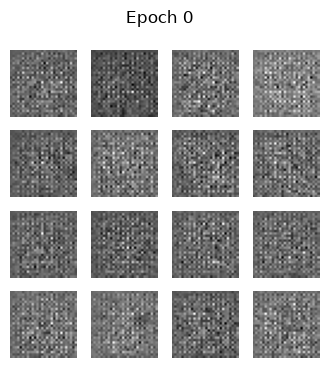

E0000 00:00:1791208270.917663   25288 meta_optimizer.cc:996] remapper failed: INVALID_ARGUMENT: Mutation::Apply error: fanout 'gradient_tape/discriminator_1/leaky_re_lu_4/LeakyRelu/LeakyReluGrad' exist for missing node 'discriminator_1/conv2d_1/BiasAdd'.


Epoch 01/50 | D loss: 1.1905 | G loss: 0.9962


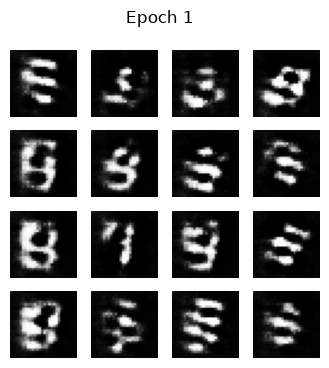

Epoch 02/50 | D loss: 1.3287 | G loss: 0.8796
Epoch 03/50 | D loss: 1.3329 | G loss: 0.8984
Epoch 04/50 | D loss: 1.3147 | G loss: 0.9047
Epoch 05/50 | D loss: 1.3232 | G loss: 0.9097


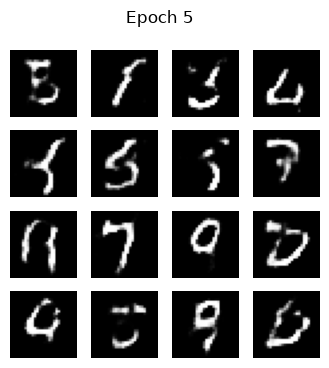

Epoch 06/50 | D loss: 1.3422 | G loss: 0.8934
Epoch 07/50 | D loss: 1.3466 | G loss: 0.8767
Epoch 08/50 | D loss: 1.3494 | G loss: 0.8586
Epoch 09/50 | D loss: 1.3514 | G loss: 0.8651
Epoch 10/50 | D loss: 1.3495 | G loss: 0.8692


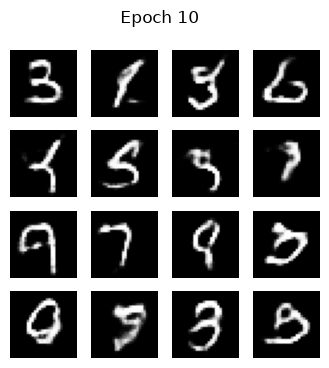

Epoch 11/50 | D loss: 1.3483 | G loss: 0.8670
Epoch 12/50 | D loss: 1.3459 | G loss: 0.8710
Epoch 13/50 | D loss: 1.3430 | G loss: 0.8612
Epoch 14/50 | D loss: 1.3439 | G loss: 0.8752
Epoch 15/50 | D loss: 1.3417 | G loss: 0.8803


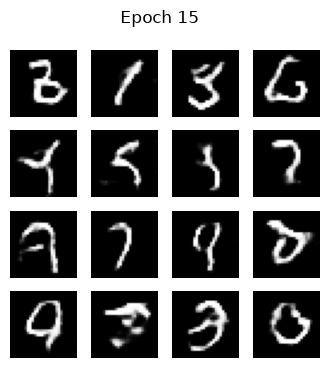

Epoch 16/50 | D loss: 1.3397 | G loss: 0.8815
Epoch 17/50 | D loss: 1.3367 | G loss: 0.8706
Epoch 18/50 | D loss: 1.3370 | G loss: 0.8905
Epoch 19/50 | D loss: 1.3336 | G loss: 0.8777
Epoch 20/50 | D loss: 1.3338 | G loss: 0.8862


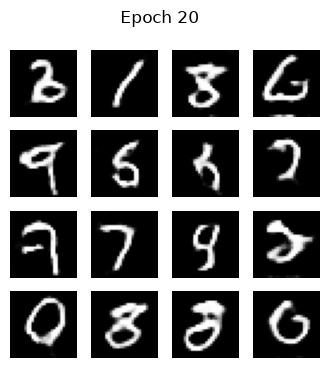

Epoch 21/50 | D loss: 1.3321 | G loss: 0.8852
Epoch 22/50 | D loss: 1.3314 | G loss: 0.8926
Epoch 23/50 | D loss: 1.3298 | G loss: 0.8858
Epoch 24/50 | D loss: 1.3323 | G loss: 0.8926
Epoch 25/50 | D loss: 1.3298 | G loss: 0.8762


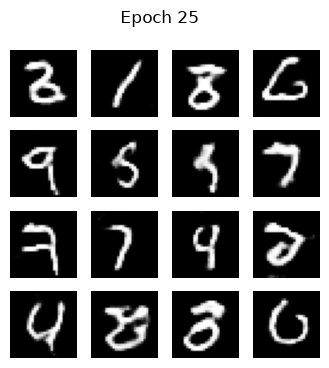

Epoch 26/50 | D loss: 1.3340 | G loss: 0.9008
Epoch 27/50 | D loss: 1.3312 | G loss: 0.8913
Epoch 28/50 | D loss: 1.3290 | G loss: 0.8786
Epoch 29/50 | D loss: 1.3320 | G loss: 0.8851
Epoch 30/50 | D loss: 1.3344 | G loss: 0.9081


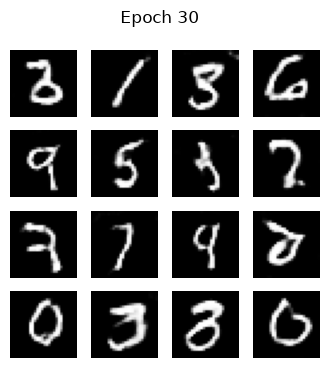

Epoch 31/50 | D loss: 1.3310 | G loss: 0.8738
Epoch 32/50 | D loss: 1.3313 | G loss: 0.8799
Epoch 33/50 | D loss: 1.3366 | G loss: 0.9005
Epoch 34/50 | D loss: 1.3335 | G loss: 0.8843
Epoch 35/50 | D loss: 1.3334 | G loss: 0.8810


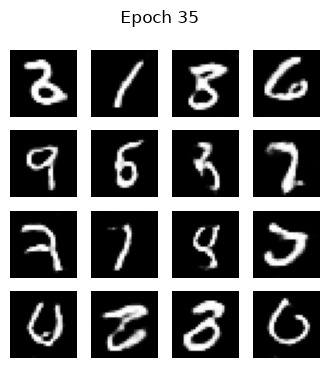

Epoch 36/50 | D loss: 1.3353 | G loss: 0.8819
Epoch 37/50 | D loss: 1.3354 | G loss: 0.8829
Epoch 38/50 | D loss: 1.3394 | G loss: 0.8926
Epoch 39/50 | D loss: 1.3358 | G loss: 0.8852
Epoch 40/50 | D loss: 1.3346 | G loss: 0.8738


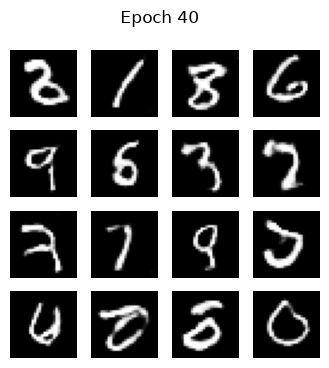

Epoch 41/50 | D loss: 1.3363 | G loss: 0.8842
Epoch 42/50 | D loss: 1.3368 | G loss: 0.8838
Epoch 43/50 | D loss: 1.3344 | G loss: 0.8797
Epoch 44/50 | D loss: 1.3376 | G loss: 0.8883
Epoch 45/50 | D loss: 1.3352 | G loss: 0.8731


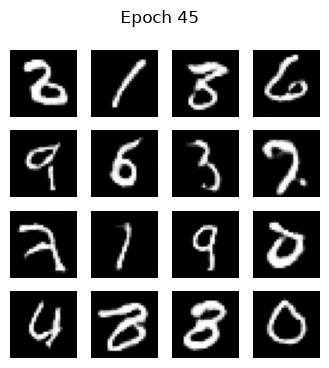

Epoch 46/50 | D loss: 1.3375 | G loss: 0.8797
Epoch 47/50 | D loss: 1.3370 | G loss: 0.8869
Epoch 48/50 | D loss: 1.3362 | G loss: 0.8781
Epoch 49/50 | D loss: 1.3369 | G loss: 0.8822
Epoch 50/50 | D loss: 1.3383 | G loss: 0.8951


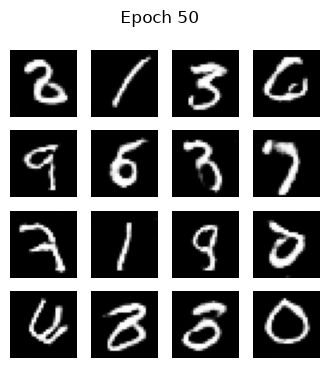

In [4]:
print("Submitted by:", ", ".join(ROLL_NOS))

EPOCHS = 50
SAVE_EVERY = 5
bce = keras.losses.BinaryCrossentropy()
os.makedirs("training_progress", exist_ok=True)
os.makedirs("final_generated_images", exist_ok=True)

# Fixed noise so progress can be compared across epochs
seed_noise = tf.random.normal([16, NOISE_DIM])

@tf.function
def train_step(real_images):
    bs = tf.shape(real_images)[0]
    noise = tf.random.normal([bs, NOISE_DIM])
    real_labels = tf.ones((bs, 1)) * 0.9      # one-sided label smoothing
    fake_labels = tf.zeros((bs, 1))

    # ---- 1) Train the Discriminator on real + generated images ----
    fake_images = generator(noise, training=True)
    with tf.GradientTape() as d_tape:
        real_pred = discriminator(real_images, training=True)
        fake_pred = discriminator(fake_images, training=True)
        d_loss = bce(real_labels, real_pred) + bce(fake_labels, fake_pred)
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))

    # ---- 2) Train the Generator through the combined GAN model ----
    # Generator wants the discriminator to label its fakes as real (1)
    noise = tf.random.normal([bs, NOISE_DIM])
    with tf.GradientTape() as g_tape:
        gan_pred = gan(noise, training=True)
        g_loss = bce(tf.ones((bs, 1)), gan_pred)
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    return d_loss, g_loss

def show_and_save(epoch):
    imgs = generator(seed_noise, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(imgs[i, :, :, 0] * 127.5 + 127.5, cmap="gray"); plt.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.savefig(f"training_progress/epoch_{epoch:03d}.png"); plt.show()

g_losses, d_losses = [], []
show_and_save(0)  # before training
for epoch in range(1, EPOCHS + 1):
    d_ep, g_ep = [], []
    for batch in train_dataset:
        d_l, g_l = train_step(batch)
        d_ep.append(float(d_l)); g_ep.append(float(g_l))
    d_losses.append(np.mean(d_ep)); g_losses.append(np.mean(g_ep))
    print(f"Epoch {epoch:02d}/{EPOCHS} | D loss: {d_losses[-1]:.4f} | G loss: {g_losses[-1]:.4f}")
    if epoch % SAVE_EVERY == 0 or epoch == 1:
        show_and_save(epoch)

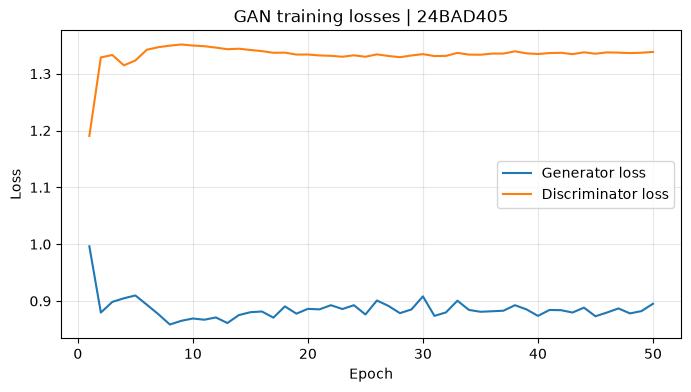

In [5]:
# Loss curves
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator loss")
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=.3)
plt.title(f"GAN training losses | {', '.join(ROLL_NOS)}"); plt.show()

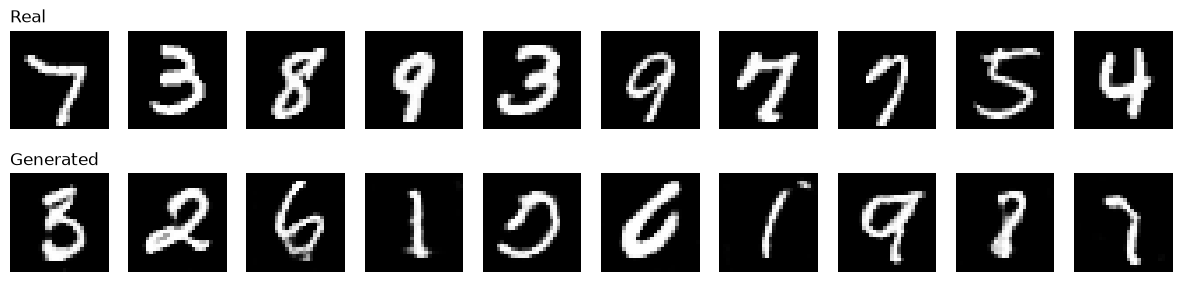

In [6]:
# Real vs generated comparison
n = 10
gen_imgs = generator(tf.random.normal([n, NOISE_DIM]), training=False).numpy()
real_imgs = train_images[np.random.choice(len(train_images), n, replace=False)]
fig, axes = plt.subplots(2, n, figsize=(15, 3.4))
for i in range(n):
    axes[0, i].imshow(real_imgs[i, :, :, 0], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(gen_imgs[i, :, :, 0], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Real", loc="left"); axes[1, 0].set_title("Generated", loc="left")
plt.show()

In [7]:
# Simple diversity check: mean pairwise pixel distance among 200 images
def mean_pairwise_dist(x):
    x = x.reshape(len(x), -1)
    d = np.linalg.norm(x[:, None] - x[None, :], axis=-1)
    return d[np.triu_indices(len(x), 1)].mean()
gen200 = generator(tf.random.normal([200, NOISE_DIM]), training=False).numpy()
real200 = train_images[np.random.choice(len(train_images), 200, replace=False)]
print("Diversity (higher = more varied)")
print(f"  Real      : {mean_pairwise_dist(real200):.2f}")
print(f"  Generated : {mean_pairwise_dist(gen200):.2f}")



Diversity (higher = more varied)
  Real      : 20.34
  Generated : 20.27


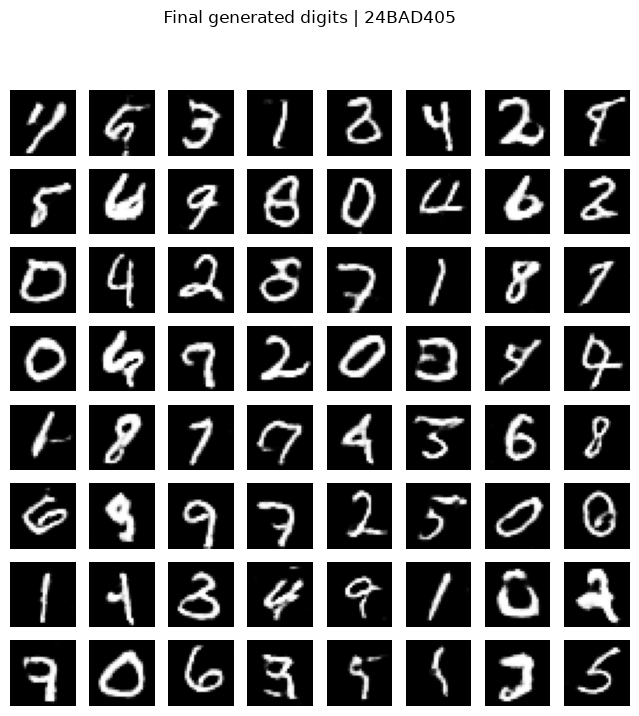

Saved: final_generated_images/, training_progress/, generator_final.keras


In [8]:
# Save final generated images (individual PNGs + a 8x8 grid) and the models
final = generator(tf.random.normal([64, NOISE_DIM]), training=False).numpy()
for i, img in enumerate(final):
    plt.imsave(f"final_generated_images/gen_{i:02d}.png", img[:, :, 0], cmap="gray")
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for ax, img in zip(axes.flat, final):
    ax.imshow(img[:, :, 0], cmap="gray"); ax.axis("off")
plt.suptitle(f"Final generated digits | {', '.join(ROLL_NOS)}")
plt.savefig("final_generated_images/grid.png"); plt.show()
generator.save("generator_final.keras"); discriminator.save("discriminator_final.keras")
print("Saved: final_generated_images/, training_progress/, generator_final.keras")

### Analysis (write in your report)
- **Quality:** Early epochs give noise/blobs; by roughly epochs 10-20 stroke-like digits appear; by epoch 50 most are recognizable.
- **Diversity:** Compare the diversity numbers above; check for mode collapse (many identical digits).
- **Losses:** GAN losses oscillate rather than steadily decrease. Stable oscillation means a balanced game; D loss near 0 means D is winning.
- **Real vs generated:** note differences in stroke thickness, broken strokes, and artifacts.